<a href="https://colab.research.google.com/github/pdeep1547-dot/dog-vs-cat-classifier/blob/main/Dog_vs_Cat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# KGAT_bf6099b378e0465e19d674e45ab33f07

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory


In [ ]:
!kaggle datasets download -d princelv84/dogsvscats

Dataset URL: https://www.kaggle.com/datasets/princelv84/dogsvscats
License(s): MIT
100% 545M/545M [00:09<00:00, 59.2MB/s]



In [ ]:
import zipfile
zip_ref = zipfile.ZipFile('/content/dogsvscats.zip', 'r')
zip_ref.extractall('/content')
zip_ref.close()

In [ ]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense,Conv2D,MaxPooling2D,Flatten,BatchNormalization,Dropout

In [ ]:
from keras.src.utils import image_dataset_utils
# generators

train_ds = keras.utils.image_dataset_from_directory(
    directory = '/content/train',
    labels = 'inferred',
    label_mode = 'int',
    batch_size = 32,
    image_size = (256,256)
)

validation_ds = keras.utils.image_dataset_from_directory(
    directory = '/content/test',
    labels = 'inferred',
    label_mode = 'int',
    batch_size = 32,
    image_size = (256,256)
)

Found 20000 files belonging to 2 classes.
Found 5000 files belonging to 2 classes.


In [ ]:
# normalize

def process(image,label):
  image = tf.cast(image/255. ,tf.float32)
  return image,label

train_ds = train_ds.map(process)
validation_ds = validation_ds.map(process)

In [ ]:
# create CNN model

model = Sequential()

model.add(Conv2D(32,kernel_size=(3,3),padding='valid', activation='relu',input_shape=(256,256,3)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'))

model.add(Conv2D(64,kernel_size=(3,3), padding='valid', activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2), strides=2, padding='valid'))

model.add(Conv2D(128, kernel_size=(3,3), padding='valid', activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2), strides=2, padding='valid'))

model.add(Conv2D(256, kernel_size=(3,3), padding='valid', activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2), strides=2, padding='valid'))

model.add(Flatten())

model.add(Dense(128, activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(1, activation='sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 254, 254, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 125, 125, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 60, 60, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     6,422,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,821,313 (26.02 MB)

 Trainable params: 6,820,353 (26.02 MB)

 Non-trainable params: 960 (3.75 KB)

In [ ]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [ ]:
# history = model.fit(train_ds, epochs=10, validation_data=validation_ds)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 70s 99ms/step - accuracy: 0.5450 - loss: 1.1081 - val_accuracy: 0.5396 - val_loss: 0.6769
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 74s 96ms/step - accuracy: 0.5405 - loss: 0.6901 - val_accuracy: 0.6186 - val_loss: 0.7079
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 63s 101ms/step - accuracy: 0.5862 - loss: 0.6625 - val_accuracy: 0.6548 - val_loss: 0.6227
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 60s 96ms/step - accuracy: 0.6282 - loss: 0.6371 - val_accuracy: 0.6364 - val_loss: 0.6447
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 63s 101ms/step - accuracy: 0.6698 - loss: 0.6023 - val_accuracy: 0.7396 - val_loss: 0.5658
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 82s 101ms/step - accuracy: 0.6727 - loss: 0.6022 - val_accuracy: 0.6986 - val_loss: 0.6054
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 78s 94ms/step - accuracy: 0.6899 - loss: 0.5860 - val_accuracy: 0.7372 - val_loss: 0.5490
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 60s 96ms/step - accuracy: 0.7125 - loss: 0.5596

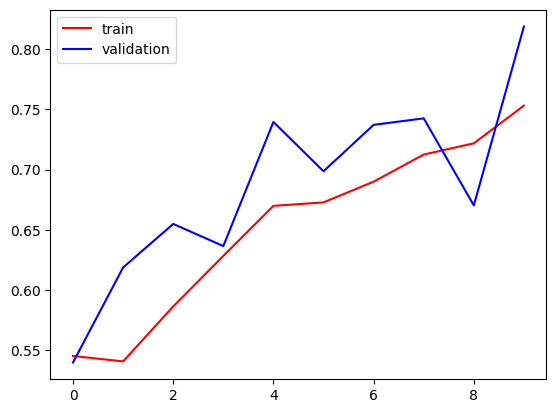

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'],color='red',label='train')
plt.plot(history.history['val_accuracy'],color='blue',label='validation')
plt.legend()
plt.show()

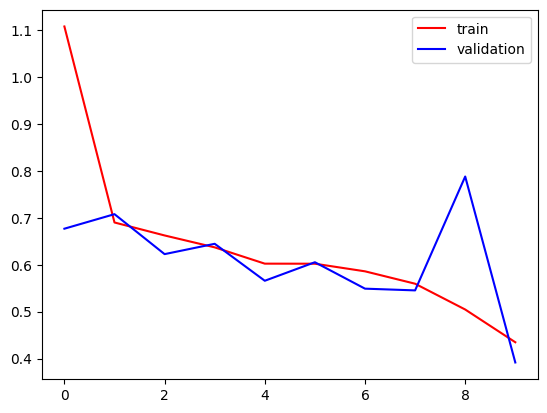

In [ ]:
plt.plot(history.history['loss'], color='red',label='train')
plt.plot(history.history['val_loss'], color='blue',label='validation')
plt.legend()
plt.show()

## How to Improve CNN Model Accuracy

Improving the accuracy of a Convolutional Neural Network (CNN) model often involves a combination of techniques. Here are some common approaches:

1.  **Data Augmentation**: Generating more training data from existing samples by applying random transformations (e.g., rotation, shifting, flipping, zooming). This helps the model generalize better and reduces overfitting.
2.  **Transfer Learning**: Using a pre-trained model on a large dataset (like ImageNet) as a starting point. This leverages features learned from a vast amount of data and often leads to higher accuracy, especially with smaller datasets.
3.  **Hyperparameter Tuning**: Optimizing learning rate, batch size, number of epochs, optimizer choice, etc.
4.  **Regularization**: Techniques like Dropout (which you already have) and L1/L2 regularization to prevent overfitting.
5.  **Model Architecture**: Using deeper or more complex architectures, or experimenting with different layer configurations.
6.  **Learning Rate Scheduling**: Dynamically adjusting the learning rate during training.
7.  **Early Stopping**: Stopping training when the validation loss stops improving to prevent overfitting.

Let's implement Data Augmentation and Transfer Learning.

### 1. Data Augmentation

Data augmentation artificially increases the size of your training dataset by creating modified versions of existing images. This helps the model become more robust to variations in the input data and reduces overfitting. Keras provides `tf.keras.layers.RandomFlip`, `tf.keras.layers.RandomRotation`, `tf.keras.layers.RandomZoom`, etc., for this purpose.

In [ ]:
import tensorflow as tf

data_augmentation = keras.Sequential(
  [
    tf.keras.layers.RandomFlip("horizontal", input_shape=(256,256,3)),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
  ]
)

# Apply data augmentation to the training dataset
# Note: Data augmentation should typically be applied as part of the model or during preprocessing for the training dataset only.
# For simplicity here, we're showing how to create an augmented dataset.
# In a real scenario, you might add these layers directly to your model or create a preprocessing pipeline.

# To integrate augmentation directly into the model:
# model = Sequential([
#     data_augmentation,
#     Conv2D(32,kernel_size=(3,3),padding='valid', activation='relu'),
#     ...
# ])

# Alternatively, we can create a new augmented training dataset.
# For image_dataset_from_directory, augmentation is usually applied inside the model definition
# or as a separate preprocessing step on the batched datasets.

# Let's create a new model with augmentation layers at the beginning
# Or, we can simply apply the augmentation to the training images before feeding them to the model.
# However, it's more efficient to have augmentation layers within the model for GPU utilization.

# For demonstration, let's show how to use it in a new model structure without retraining the old one
# We will use the augmented data with a new model or modify the existing one. For now, just showing the augmentation setup.


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Let's rebuild the model with the data augmentation layers included at the beginning. This ensures augmentation is only applied during training.

In [ ]:
# Re-create the CNN model with data augmentation
model_aug = Sequential()

model_aug.add(data_augmentation) # Add augmentation layers here

model_aug.add(Conv2D(32,kernel_size=(3,3),padding='valid', activation='relu'))
model_aug.add(BatchNormalization())
model_aug.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'))

model_aug.add(Conv2D(64,kernel_size=(3,3), padding='valid', activation='relu'))
model_aug.add(BatchNormalization())
model_aug.add(MaxPooling2D(pool_size=(2,2), strides=2, padding='valid'))

model_aug.add(Conv2D(128, kernel_size=(3,3), padding='valid', activation='relu'))
model_aug.add(BatchNormalization())
model_aug.add(MaxPooling2D(pool_size=(2,2), strides=2, padding='valid'))

model_aug.add(Conv2D(256, kernel_size=(3,3), padding='valid', activation='relu'))
model_aug.add(BatchNormalization())
model_aug.add(MaxPooling2D(pool_size=(2,2), strides=2, padding='valid'))

model_aug.add(Flatten())

model_aug.add(Dense(128, activation='relu'))
model_aug.add(Dropout(0.3))
model_aug.add(Dense(64, activation='relu'))
model_aug.add(Dropout(0.2))
model_aug.add(Dense(1, activation='sigmoid'))

model_aug.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

print("Model with Data Augmentation Summary:")
model_aug.summary()

print("\nTraining model with Data Augmentation...")
history_aug = model_aug.fit(train_ds, epochs=10, validation_data=validation_ds)


Model with Data Augmentation Summary:


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 254, 254, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 125, 125, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 60, 60, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │     6,422,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,821,313 (26.02 MB)

 Trainable params: 6,820,353 (26.02 MB)

 Non-trainable params: 960 (3.75 KB)


Training model with Data Augmentation...
Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 122s 180ms/step - accuracy: 0.5580 - loss: 1.1139 - val_accuracy: 0.6022 - val_loss: 0.6575
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 111s 178ms/step - accuracy: 0.6457 - loss: 0.6314 - val_accuracy: 0.6772 - val_loss: 0.5849
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 114s 183ms/step - accuracy: 0.7067 - loss: 0.5682 - val_accuracy: 0.7528 - val_loss: 0.5230
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 115s 183ms/step - accuracy: 0.7448 - loss: 0.5143 - val_accuracy: 0.7664 - val_loss: 0.4973
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 111s 178ms/step - accuracy: 0.7876 - loss: 0.4545 - val_accuracy: 0.8202 - val_loss: 0.4081
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 114s 183ms/step - accuracy: 0.8210 - loss: 0.3909 - val_accuracy: 0.8228 - val_loss: 0.3933
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 114s 183ms/step - accuracy: 0.8551 - loss: 0.3317 - val_accuracy: 0.8384 - val_loss: 0.3574
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━

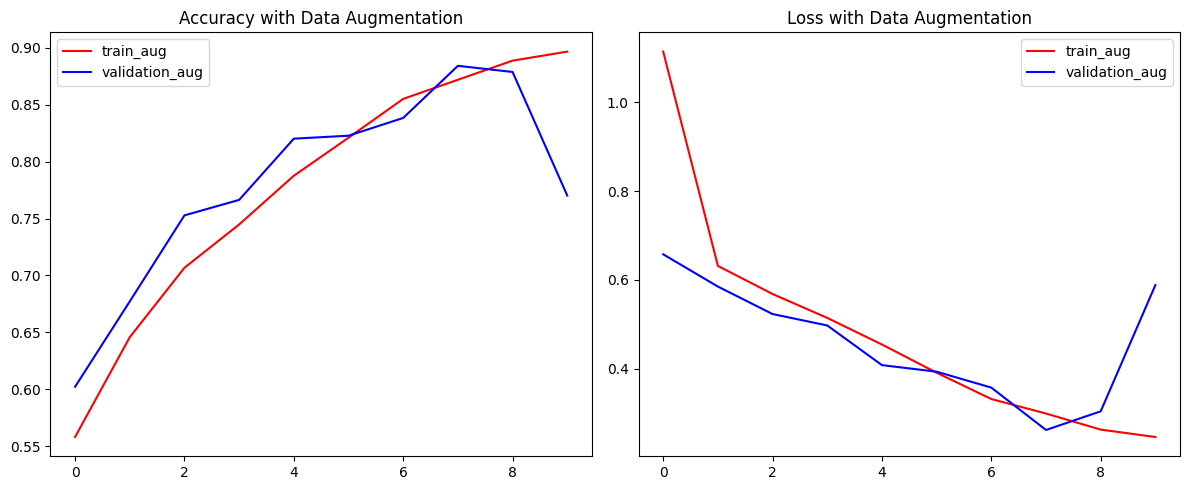

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_aug.history['accuracy'],color='red',label='train_aug')
plt.plot(history_aug.history['val_accuracy'],color='blue',label='validation_aug')
plt.title('Accuracy with Data Augmentation')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_aug.history['loss'], color='red',label='train_aug')
plt.plot(history_aug.history['val_loss'], color='blue',label='validation_aug')
plt.title('Loss with Data Augmentation')
plt.legend()

plt.tight_layout()
plt.show()


### 2. Transfer Learning

Transfer learning is a technique where a model trained on one task is re-purposed for a second related task. For image classification, this means using a pre-trained CNN (like VGG16, ResNet, EfficientNet) that has learned powerful features from a very large dataset (e.g., ImageNet). You can then fine-tune this model on your specific dataset.

There are two main approaches:

1.  **Feature Extraction**: Use the pre-trained model as a fixed feature extractor. The convolutional base of the pre-trained model is used to extract features, and a new classifier is trained on top of these features.
2.  **Fine-tuning**: Unfreeze some of the top layers of the pre-trained model's convolutional base and jointly train both the unfrozen layers and the newly added classifier layers.

In [ ]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input

# Load the VGG16 model pre-trained on ImageNet data, excluding the top (classification) layers.
conv_base = VGG16(weights='imagenet', include_top=False, input_shape=(256, 256, 3))

# Freeze the convolutional base to use it as a feature extractor
conv_base.trainable = False

# Create a new model on top of the pre-trained base
model_tl = Sequential([
    conv_base,
    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

model_tl.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

print("Transfer Learning Model Summary (VGG16 Feature Extractor):")
model_tl.summary()

print("\nTraining Transfer Learning Model...")
history_tl = model_tl.fit(train_ds, epochs=10, validation_data=validation_ds)

Transfer Learning Model Summary (VGG16 Feature Extractor):


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 8, 8, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 256)            │     8,388,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,103,809 (88.13 MB)

 Trainable params: 8,389,121 (32.00 MB)

 Non-trainable params: 14,714,688 (56.13 MB)


Training Transfer Learning Model...
Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 191s 272ms/step - accuracy: 0.8789 - loss: 0.3092 - val_accuracy: 0.9104 - val_loss: 0.2006
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 170s 272ms/step - accuracy: 0.9207 - loss: 0.1944 - val_accuracy: 0.9358 - val_loss: 0.1504
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 172s 276ms/step - accuracy: 0.9330 - loss: 0.1704 - val_accuracy: 0.9400 - val_loss: 0.1439
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 179s 287ms/step - accuracy: 0.9311 - loss: 0.1651 - val_accuracy: 0.9422 - val_loss: 0.1414
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 172s 275ms/step - accuracy: 0.9380 - loss: 0.1408 - val_accuracy: 0.9410 - val_loss: 0.1432
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 173s 276ms/step - accuracy: 0.9454 - loss: 0.1292 - val_accuracy: 0.9408 - val_loss: 0.1416
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 172s 275ms/step - accuracy: 0.9479 - loss: 0.1238 - val_accuracy: 0.9390 - val_loss: 0.1498
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━

### Further Steps for Improvement:

*   **Fine-tuning the pre-trained model**: After training the classifier on top of the frozen convolutional base, you can unfreeze some of the later layers of the convolutional base and continue training the entire model with a very low learning rate. This allows the pre-trained model to adapt its features more specifically to your dataset.
*   **Learning Rate Schedule**: Implement a learning rate scheduler (e.g., ReduceLROnPlateau, CosineAnnealing) to dynamically adjust the learning rate during training, which can help in finding better optima.
*   **Early Stopping**: Use a callback to stop training when the validation loss no longer improves for a certain number of epochs, preventing overfitting.
*   **Different Pre-trained Models**: Experiment with other powerful pre-trained models like ResNet50, InceptionV3, EfficientNet, etc., as some might be better suited for your specific task.

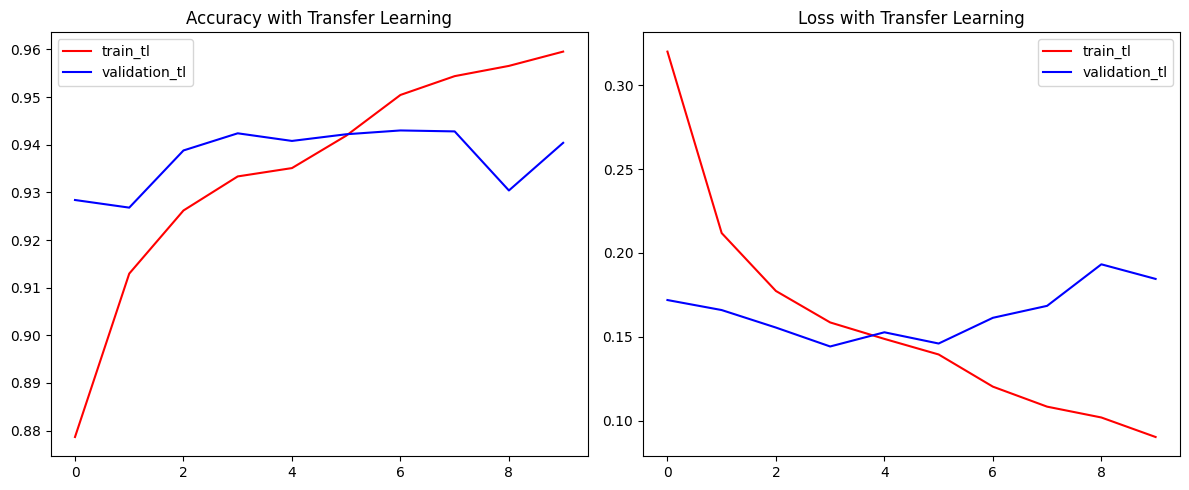

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_tl.history['accuracy'],color='red',label='train_tl')
plt.plot(history_tl.history['val_accuracy'],color='blue',label='validation_tl')
plt.title('Accuracy with Transfer Learning')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_tl.history['loss'], color='red',label='train_tl')
plt.plot(history_tl.history['val_loss'], color='blue',label='validation_tl')
plt.title('Loss with Transfer Learning')
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:
import numpy as np
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.vgg16 import preprocess_input

CLASS_NAMES = train_generator.class_names

def predict_leaf(image_path):
    img = image.load_img(image_path, target_size=(256, 256))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    # img_array = preprocess_input(img_array)

    prediction = model.predict(img_array, verbose=0)[0]

    predicted_index = np.argmax(prediction)
    predicted_class = CLASS_NAMES[predicted_index]
    confidence = prediction[predicted_index] * 100

    print(f"Predicted class: {predicted_class}")
    print(f"Confidence: {confidence:.2f}%")

# Example usage:
# predict_leaf('/content/tomato/val/Tomato___healthy/001_0045.JPG')